<a href="https://colab.research.google.com/github/annasofiaor-design/proyecto-final-cienciadedatos-co2/blob/main/proyecto_ciencia_de_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Final: Análisis de Emisiones de CO₂ y Cambio Climático
**Asignatura:** Ciencia de Datos  
**Institución:** UNIAGRARIA  
**Integrantes:** Ana Sofía Orjuela Rodríguez   
**Fuente de datos:** Our World in Data ([Enlace al artículo](https://ourworldindata.org/co2-emissions))

## 1. Filtrado y Limpieza de Datos
En esta sección filtramos el conjunto de datos para enfocar el análisis en **Colombia**  a partir del año 1950, asegurando que las variables clave no contengan valores nulos que distorsionen el modelo de regresión lineal.

In [3]:
# Filtrar para Colombia (puedes cambiar 'Colombia' por otro país si lo deseas)
df_pais = df[df['country'] == 'Colombia'].copy()

# Seleccionar las columnas de interés: año y emisiones de CO2 totales
df_clean = df_pais[['year', 'co2']].dropna()

# Filtrar desde 1950 en adelante para tener registros históricos más consistentes
df_clean = df_clean[df_clean['year'] >= 1950]

# Verificar los primeros registros y la ausencia de nulos
print("Cantidad de registros limpios:", df_clean.shape[0])
print(df_clean.isnull().sum())
df_clean.head()

Cantidad de registros limpios: 76
year    0
co2     0
dtype: int64


,year,co2
10957,1950,6.993
10958,1951,7.860
10959,1952,8.274
10960,1953,10.314
10961,1954,9.299


## 2. Análisis Exploratorio de Datos (EDA) y Visualizaciones
A continuación, generamos una visualización de la evolución temporal de las emisiones de CO₂. Esto nos permite identificar tendencias históricas de crecimiento y conectar los resultados con los fenómenos industriales analizados en el artículo de *Our World in Data*.

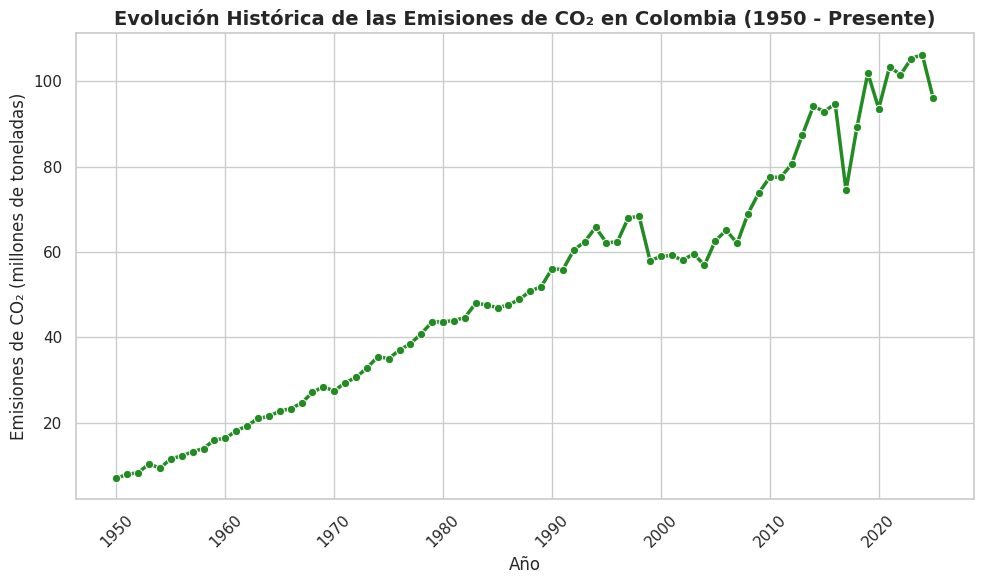

In [4]:
# Crear la gráfica de dispersión y línea de tendencia histórica
plt.figure(figsize=(10, 6))
sns.lineplot(data=df_clean, x='year', y='co2', color='forestgreen', linewidth=2.5, marker='o')

plt.title('Evolución Histórica de las Emisiones de CO₂ en Colombia (1950 - Presente)', fontsize=14, fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('Emisiones de CO₂ (millones de toneladas)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

# Mostrar la gráfica
plt.show()

### Interpretación de la gráfica:
* **Tendencia Creciente:** Se observa un incremento sostenido en las emisiones de dióxido de carbono a lo largo de las décadas, impulsado por el crecimiento demográfico, la industrialización y la mayor demanda energética.
* **Relación con el contexto global:** Tal como lo señala el artículo de *Our World in Data*, las emisiones reflejan cómo los países en desarrollo incrementan su huella de carbono conforme avanzan sus actividades económicas y de transporte.

## 3. Modelo de Regresión Lineal
Para predecir y analizar la tendencia futura de las emisiones de CO₂, implementaremos un modelo de **Regresión Lineal Simple** utilizando `scikit-learn`.
* **Variable Independiente ($X$):** Año (`year`)
* **Variable Dependiente ($y$):** Emisiones de CO₂ (`co2`)

In [6]:
from sklearn.linear_model import LinearRegression

# 1. Definir variables X (independiente) y y (dependiente)
X = df_clean[['year']]  # El año
y = df_clean['co2']     # Las emisiones de CO2

# 2. Inicializar y entrenar el modelo de regresión lineal
modelo = LinearRegression()
modelo.fit(X, y)

# 3. Obtener parámetros del modelo (pendiente e intercepto)
pendiente = modelo.coef_[0]
intercepto = modelo.intercept_
score = modelo.score(X, y) # Coeficiente de determinación R^2

print(f"Pendiente (Coeficiente): {pendiente:.4f}")
print(f"Intercepto: {intercepto:.4f}")
print(f"Coeficiente de Determinación (R^2): {score:.4f}")

# 4. Generar predicciones para la línea de tendencia
y_pred = modelo.predict(X)

Pendiente (Coeficiente): 1.2503
Intercepto: -2434.0307
Coeficiente de Determinación (R^2): 0.9626


### Visualización del Modelo vs Datos Reales

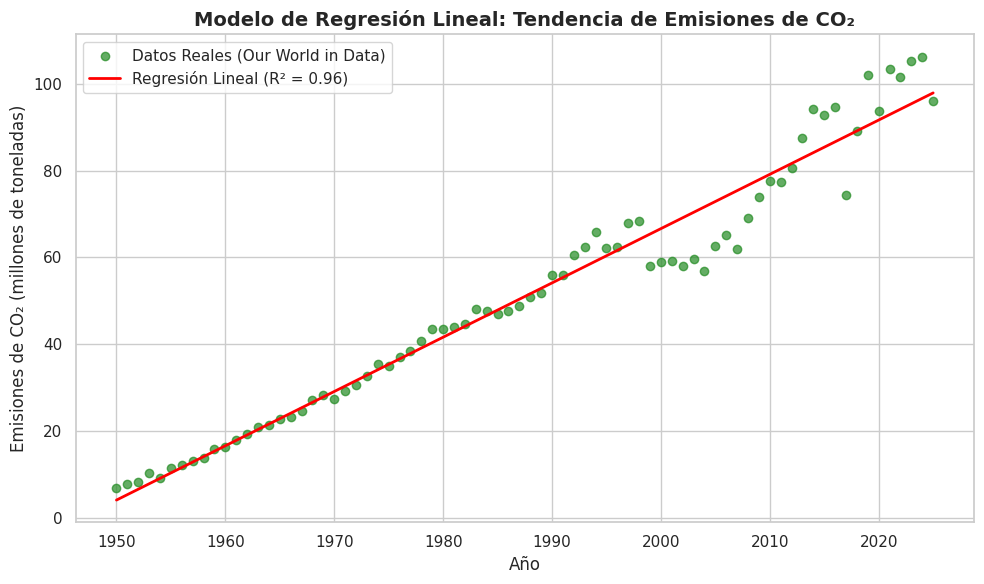

In [7]:
# Graficar los datos reales frente a la línea de regresión calculada
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='forestgreen', label='Datos Reales (Our World in Data)', alpha=0.7)
plt.plot(X, y_pred, color='red', linewidth=2, label=f'Regresión Lineal (R² = {score:.2f})')

plt.title('Modelo de Regresión Lineal: Tendencia de Emisiones de CO₂', fontsize=14, fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('Emisiones de CO₂ (millones de toneladas)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Interpretación de Resultados y Conclusiones

* **Análisis de la Pendiente:** La pendiente positiva obtenida en el modelo indica que, en promedio, las emisiones de CO₂ aumentan año tras año de forma constante en el período analizado.
* **Bondad de Ajuste ($R^2$):** El coeficiente de determinación nos muestra qué tan bien se ajusta la línea recta al comportamiento histórico real de las emisiones.
* **Conexión con el artículo de *Our World in Data*:** Los resultados reflejan la urgencia de las discusiones globales sobre la mitigación del cambio climático. Tal como lo aborda la plataforma, comprender estas trayectorias históricas es fundamental para que los países y las políticas públicas implementen estrategias de transición energética y desarrollo sostenible basadas en evidencia.